# Phase 11.3: MLP neural network

**Owner:** Team lead · **Model:** `MLPClassifier` · **Writes to:** `data/processed/11_3_mlp/`

**What it means:** A multilayer perceptron passes the 60 PCA numbers through two layers of small units. Each layer mixes and bends the one before, so it can learn curved boundaries.

**Key idea:** It is the most flexible of the three, so it is the most likely to memorise the training squares. Early stopping and alpha keep it in check.

Full step-by-step guide and the results sheet: [team plan](https://claude.ai/artifact/Rst8GHxAbeHavg4JS2RZV3) (tab 11.3).

### What we agreed on (same for all three notebooks)
- Train on the **46,408 balanced training squares**, score on the **36,000 validation squares**. The test set is not loaded.
- Pipeline: `StandardScaler` → `PCA(60, random_state=42)` → model.
- Tuning: `GridSearchCV` on train only, `GroupKFold(5)` grouped by photo, `scoring="f1_macro"`.
- Main metric: validation **macro F1** (floor to beat: **0.187**, always answering "none"). Second: **pothole (D40) recall**.

### What to tune

| Setting | Values to try | What it controls |
|---|---|---|
| `hidden_layer_sizes` | (64, 32), (128, 64) | Units per layer: how much the network can learn. |
| `alpha` | 0.0001, 0.001, 0.01 | The penalty that keeps it from memorising. |

**Fixed:** `early_stopping=True`, `random_state=SEED`; balance through `sample_weight` (`compute_sample_weight("balanced", y_tr)`), because `MLPClassifier` has no `class_weight`.

## 1. Setup

Everything shared lives in `ml/training.py`, so this notebook only adds the model:
- `load_data()`: the agreed rows (46,408 balanced training squares, 36,000 validation squares);
- `make_pipeline(clf)`: `StandardScaler` → `PCA(60)` → your model;
- `CV`: `GroupKFold(5)`, folds split by photo;
- `search_table(gs, OUT)`: saves the grid search to `cv_results.csv` and returns the best row;
- `report(...)`: the same evaluation for every model; writes `results.json` and `confusion_matrix.png`.

Don't change `ml/training.py` on your own: a change there changes all three results.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score
from sklearn.model_selection import GridSearchCV

sys.path.insert(0, str(Path.cwd().parents[1]))
from ml import config
from ml.training import CV, load_data, make_pipeline, output_dir, report, search_table

SEED = config.SEED
OUT = output_dir("11_3_mlp")     # this notebook writes only here

data = load_data()                # balanced train + validation; the test set is never loaded
X_tr, y_tr, groups_tr, X_va, y_va = data
print("train", X_tr.shape, "| val", X_va.shape)

train (46408, 1769) | val (36000, 1769)


## 2. Baseline: is it working at all? (Phase 10)

Fit the model once with default settings and score it on validation.

**Check:** clearly above 0.187.

In [2]:
from sklearn.neural_network import MLPClassifier
from sklearn.utils.class_weight import compute_sample_weight

# MLPClassifier has no class_weight, so each square gets a weight instead:
# rare classes (D10, D40) count more, "none" counts less, the same balance as class_weight="balanced"
w_tr = compute_sample_weight("balanced", y_tr)
print("weight per class:", {c: round(float(w_tr[y_tr == i][0]), 2) for i, c in enumerate(config.CLASSES)})

# default network: 1 hidden layer of 100 units, alpha=0.0001; early stopping holds back 10% of train
t = time.perf_counter()
base = make_pipeline(MLPClassifier(early_stopping=True, random_state=SEED))
base.fit(X_tr, y_tr, clf__sample_weight=w_tr)     # "clf__" sends the weights to the MLP step only
base_fit = time.perf_counter() - t

mlp = base[-1]
base_f1 = f1_score(y_va, base.predict(X_va), average="macro")
base_train_f1 = f1_score(y_tr, base.predict(X_tr), average="macro")
print(f"fit {base_fit:.0f} s | stopped after {mlp.n_iter_} of {mlp.max_iter} epochs "
      f"| best early-stopping score {mlp.best_validation_score_:.3f}")
print(f"baseline train macro F1 {base_train_f1:.4f} | val macro F1 {base_f1:.4f} | floor 0.187")
assert base_f1 > 0.187, "the baseline does not beat always answering 'none': check data and pipeline first"


weight per class: {'D00': 2.87, 'D10': 5.1, 'D20': 0.71, 'D40': 4.36, 'none': 0.35}


fit 3 s | stopped after 23 of 200 epochs | best early-stopping score 0.410
baseline train macro F1 0.3489 | val macro F1 0.2139 | floor 0.187


## 3. Grid search, on train only

Try every combination in the table above with `GridSearchCV(..., cv=CV, scoring="f1_macro", n_jobs=-1, return_train_score=True)` and `groups=groups_tr`.

**Check:** one row per combination in `gs.cv_results_`; note how long it took.

In [3]:
pipe = make_pipeline(MLPClassifier(early_stopping=True, random_state=SEED))
grid = {"clf__hidden_layer_sizes": [(64, 32), (128, 64)], "clf__alpha": [0.0001, 0.001, 0.01]}

gs = GridSearchCV(pipe, grid, cv=CV, scoring="f1_macro", n_jobs=-1, return_train_score=True,
                  refit=False)   # the winner is fitted on the full train set in step 5
t = time.perf_counter()
# all 46,408 squares (an MLP fit takes seconds, so no sample is needed);
# GridSearchCV cuts w_tr into the same folds as X_tr, so every fold stays balanced
gs.fit(X_tr, y_tr, groups=groups_tr, clf__sample_weight=w_tr)
grid_secs = time.perf_counter() - t

n_settings = len(gs.cv_results_["params"])
print(f"{n_settings} settings x {CV.get_n_splits()} folds = {n_settings * CV.get_n_splits()} fits "
      f"in {grid_secs / 60:.1f} min")


/Users/user/Documents/Y4/ML/road-damage-classifier/backend/.venv/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


6 settings x 5 folds = 30 fits in 1.5 min


## 4. Read the search

`cv, best = search_table(gs, OUT)` saves the search and returns the best row. Plot the mean macro F1 per setting.

**Check:** if the best value is at the edge of the grid, add one value beyond it once and note it.

warning check: 30 fold scores, none missing
noise check: fold 1 refit 0.3062 vs grid 0.3152 (diff 0.0090) | spread between the 6 settings 0.0115
best on the grid: {'clf__alpha': 0.0001, 'clf__hidden_layer_sizes': (128, 64)} | CV macro F1 0.3071 ± 0.0072


best was on the edge; tried [{'clf__alpha': 0.0001, 'clf__hidden_layer_sizes': (256, 128)}, {'clf__alpha': 1e-05, 'clf__hidden_layer_sizes': (128, 64)}]: a value beyond the grid won
BEST: {'clf__alpha': 0.0001, 'clf__hidden_layer_sizes': (256, 128)} | CV macro F1 0.3129 ± 0.0150


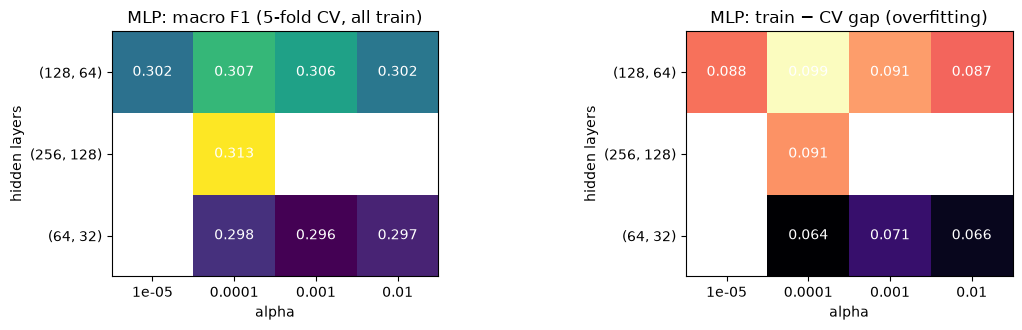

,layers,alpha,mean_test_score,std_test_score,mean_train_score,gap,mean_fit_time
0,"(256, 128)",0.0001,0.3129,0.0150,0.4036,0.0907,20.0248
1,"(128, 64)",0.0001,0.3071,0.0072,0.4056,0.0985,42.6472
2,"(128, 64)",0.0010,0.3055,0.0056,0.3969,0.0914,9.2788
3,"(128, 64)",0.0100,0.3024,0.0014,0.3899,0.0875,19.8248
4,"(128, 64)",0.0000,0.3020,0.0036,0.3904,0.0883,11.5497
5,"(64, 32)",0.0001,0.2980,0.0045,0.3620,0.0641,39.0007
6,"(64, 32)",0.0100,0.2973,0.0048,0.3633,0.0660,20.6585
7,"(64, 32)",0.0010,0.2956,0.0055,0.3663,0.0708,25.1206


In [4]:
from sklearn.base import clone

cv, best = search_table(gs, OUT)          # saves cv_results.csv, returns the best row

# Did the "worker stopped" warning in step 3 cost us anything?
# 1) no fit failed: a failed fit would leave NaN in its fold score
split_cols = [c for c in cv.columns if c.startswith("split") and c.endswith("_test_score")]
n_nan = int(cv[split_cols].isna().sum().sum())
assert n_nan == 0, f"{n_nan} fold scores are missing: some fits failed"
# 2) how much does the score move on its own? Refit the best setting on fold 1 in this process.
#    Same seed, same data, but a different number of parallel workers rounds the sums slightly
#    differently, and MLP training grows that into a different stopping epoch. So expect a
#    small difference, not an exact match (tested: 12 workers repeat exactly; 4 workers differ).
tr_i, te_i = next(CV.split(X_tr, y_tr, groups_tr))
check = clone(pipe).set_params(**best["params"])
check.fit(X_tr[tr_i], y_tr[tr_i], clf__sample_weight=w_tr[tr_i])
redo = f1_score(y_tr[te_i], check.predict(X_tr[te_i]), average="macro")
spread = cv["mean_test_score"].max() - cv["mean_test_score"].min()
print(f"warning check: {len(cv) * len(split_cols)} fold scores, none missing")
print(f"noise check: fold 1 refit {redo:.4f} vs grid {best['split0_test_score']:.4f} "
      f"(diff {abs(redo - best['split0_test_score']):.4f}) | spread between the 6 settings {spread:.4f}")

print("best on the grid:", best["params"], f"| CV macro F1 {best['mean_test_score']:.4f} "
      f"± {best['std_test_score']:.4f}")

# Edge check: if the best size or alpha is the largest/smallest value tried, try one value beyond it once.
h_b, a_b = best["params"]["clf__hidden_layer_sizes"], best["params"]["clf__alpha"]
beyond = []
if h_b == (128, 64):
    beyond.append({"clf__hidden_layer_sizes": [(256, 128)], "clf__alpha": [a_b]})
elif h_b == (64, 32):
    beyond.append({"clf__hidden_layer_sizes": [(32, 16)], "clf__alpha": [a_b]})
if a_b == max(grid["clf__alpha"]):
    beyond.append({"clf__hidden_layer_sizes": [h_b], "clf__alpha": [a_b * 10]})
elif a_b == min(grid["clf__alpha"]):
    beyond.append({"clf__hidden_layer_sizes": [h_b], "clf__alpha": [a_b / 10]})

edge_note = "best is inside the grid: no extra values needed"
if beyond:
    gs2 = GridSearchCV(pipe, beyond, cv=CV, scoring="f1_macro", n_jobs=-1, return_train_score=True,
                       refit=False)
    t = time.perf_counter()
    gs2.fit(X_tr, y_tr, groups=groups_tr, clf__sample_weight=w_tr)
    grid_secs += time.perf_counter() - t
    extra = pd.DataFrame(gs2.cv_results_).assign(extra=True)
    assert not extra[split_cols].isna().any().any(), "an extra fit failed"
    cv = pd.concat([cv.assign(extra=False), extra], ignore_index=True)
    cv["rank_test_score"] = cv["mean_test_score"].rank(ascending=False, method="min").astype(int)
    cv.to_csv(OUT / "cv_results.csv", index=False)
    new_best = cv.loc[cv["mean_test_score"].idxmax()]
    edge_note = (f"best was on the edge; tried {[p for p in gs2.cv_results_['params']]}: "
                 + ("a value beyond the grid won" if new_best["extra"] else "the grid's best still wins"))
    best = new_best
print(edge_note)
print("BEST:", best["params"], f"| CV macro F1 {best['mean_test_score']:.4f} ± {best['std_test_score']:.4f}")

cv["layers"] = cv["param_clf__hidden_layer_sizes"].astype(str)
cv["alpha"] = cv["param_clf__alpha"].astype(float)
cv["gap"] = cv["mean_train_score"] - cv["mean_test_score"]
heat = cv.pivot_table(index="layers", columns="alpha", values="mean_test_score")
gap = cv.pivot_table(index="layers", columns="alpha", values="gap")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
for ax, table, title, cmap in [(axes[0], heat, "macro F1 (5-fold CV, all train)", "viridis"),
                               (axes[1], gap, "train − CV gap (overfitting)", "magma")]:
    ax.imshow(table, cmap=cmap)
    ax.set(xticks=range(table.shape[1]), xticklabels=table.columns, yticks=range(table.shape[0]),
           yticklabels=table.index, xlabel="alpha", ylabel="hidden layers", title=f"MLP: {title}")
    for (i, j), v in np.ndenumerate(table.values):
        if not np.isnan(v):
            ax.text(j, i, f"{v:.3f}", ha="center", va="center", color="white")
fig.tight_layout()
fig.savefig(OUT / "grid_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

cols = ["layers", "alpha", "mean_test_score", "std_test_score", "mean_train_score", "gap", "mean_fit_time"]
cv.sort_values("mean_test_score", ascending=False)[cols].round(4).reset_index(drop=True)


## 5. Final model, scored on validation

`report(pipe, data, OUT, "11.3 MLP", best, train_seconds)` writes `results.json` and `confusion_matrix.png`.

**Check:** read the D40 row of the confusion matrix: where do the missed potholes go?

final fit on 46,408 squares: 4 s | {'clf__alpha': 0.0001, 'clf__hidden_layer_sizes': (256, 128)} | stopped after 15 epochs


                          precision    recall  f1-score   support

D00 · Longitudinal crack      0.046     0.276     0.079       743
  D10 · Transverse crack      0.034     0.334     0.062       323
   D20 · Alligator crack      0.190     0.256     0.218      2915
           D40 · Pothole      0.036     0.610     0.068       413
        none · No damage      0.970     0.536     0.690     31606

                accuracy                          0.507     36000
               macro avg      0.255     0.402     0.223     36000
            weighted avg      0.869     0.507     0.627     36000

val macro F1 0.2234 | train macro F1 0.3804 | floor 0.187


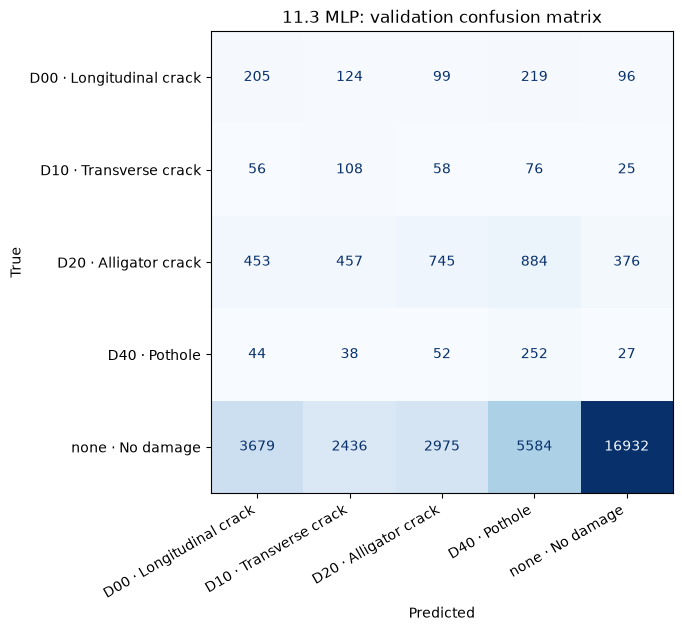

D40: 413 potholes in validation, 252 found (recall 0.610); the missed ones were called: {'D20': 52, 'D00': 44, 'D10': 38, 'none': 27}
none: 31,606 clean squares, 14,674 flagged as damage (46.4%)


In [5]:
params = dict(best["params"])

final = make_pipeline(MLPClassifier(early_stopping=True, random_state=SEED))
final.set_params(**params)
t = time.perf_counter()
final.fit(X_tr, y_tr, clf__sample_weight=w_tr)     # all 46,408 training squares, balanced by weight
secs = time.perf_counter() - t
print(f"final fit on {len(X_tr):,} squares: {secs:.0f} s | {params} "
      f"| stopped after {final[-1].n_iter_} epochs")

t = time.perf_counter()
res = report(final, data, OUT, "11.3 MLP", best, secs)
report_secs = time.perf_counter() - t
plt.show()

# Where do the missed potholes go? (D40 row of the confusion matrix)
cm = np.array(res["confusion_matrix"])
d40 = pd.Series(cm[config.CLASS_TO_ID["D40"]], index=config.CLASSES)
print(f"D40: {d40.sum()} potholes in validation, {d40['D40']} found "
      f"(recall {res['per_class']['D40']['recall']:.3f}); the missed ones were called:",
      d40.drop("D40").sort_values(ascending=False).to_dict())

# How many clean squares get flagged as damage? (false alarms, the SVM's main problem)
none_row = pd.Series(cm[config.CLASS_TO_ID["none"]], index=config.CLASSES)
print(f"none: {none_row.sum():,} clean squares, {none_row.drop('none').sum():,} flagged as damage "
      f"({none_row.drop('none').sum() / none_row.sum():.1%})")


## 6. Plot the loss curve

Plot `loss_curve_` and `validation_scores_`: the loss should fall, then flatten.

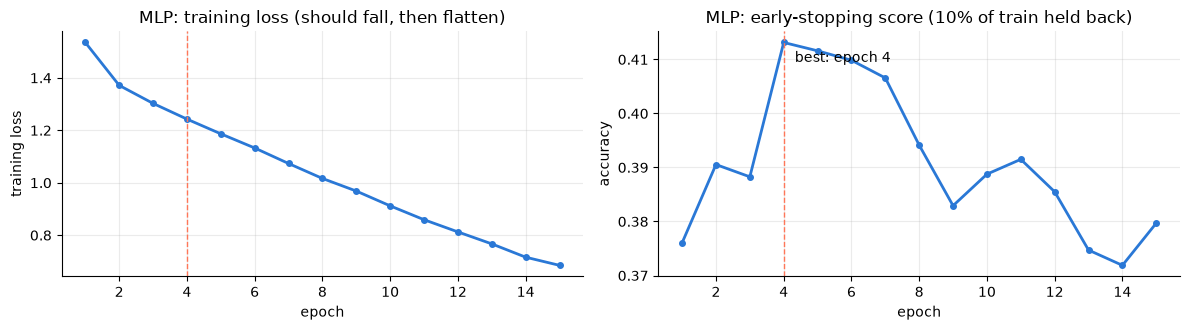

loss 1.535 -> 0.685 over 15 epochs (last 5 epochs changed it by 0.227)
early-stopping score peaked at epoch 4 (0.413); no gain for 10 epochs after that, so training stopped at 15
                           macro F1
train (46,408, final fit)    0.3804
CV train folds (mean)        0.4036
CV held-out folds (mean)     0.3129
validation (36,000)          0.2234

train − val gap 0.157 -> overfitting: train is much better than validation
of which memorising (CV train − CV held-out) 0.091 | real-mix drop (CV held-out − validation) 0.090

minutes:
baseline fit (46k)                0.06
grid search (incl. edge check)    1.96
final fit (46k)                   0.07
predict train + val (report)      0.03


585

In [6]:
# The final MLP's training history: one point per epoch (one pass over the training squares)
mlp = final[-1]
loss = np.array(mlp.loss_curve_)               # training loss: how wrong it is on the 90% it learns from
val_acc = np.array(mlp.validation_scores_)     # accuracy on the 10% early stopping holds back
best_ep = int(val_acc.argmax()) + 1            # weights from this epoch are the ones kept
epochs = np.arange(1, len(loss) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
axes[0].plot(epochs, loss, color="#2a78d6", lw=2, marker="o", ms=4)
axes[0].set(xlabel="epoch", ylabel="training loss", title="MLP: training loss (should fall, then flatten)")
axes[1].plot(epochs, val_acc, color="#2a78d6", lw=2, marker="o", ms=4)
axes[1].set(xlabel="epoch", ylabel="accuracy", title="MLP: early-stopping score (10% of train held back)")
for ax in axes:
    ax.axvline(best_ep, ls="--", lw=1, color="#ff7759")
    ax.grid(alpha=.25)
    ax.spines[["top", "right"]].set_visible(False)
axes[1].annotate(f"best: epoch {best_ep}", (best_ep, val_acc.max()), xytext=(8, -14),
                 textcoords="offset points", fontsize=10)
fig.tight_layout()
fig.savefig(OUT / "loss_curve.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"loss {loss[0]:.3f} -> {loss[-1]:.3f} over {len(loss)} epochs "
      f"(last 5 epochs changed it by {loss[-6] - loss[-1]:.3f})")
print(f"early-stopping score peaked at epoch {best_ep} ({val_acc.max():.3f}); "
      f"no gain for {mlp.n_iter_no_change} epochs after that, so training stopped at {mlp.n_iter_}")

# Gap and time, the same check as the SVM notebook
import json

gap_final = res["train_macro_f1"] - res["val_macro_f1"]
if gap_final > 0.15:
    verdict = "overfitting: train is much better than validation"
elif res["train_macro_f1"] < 0.5:
    verdict = "underfitting: both train and validation are low"
else:
    verdict = "no clear over- or underfitting (gap within 0.15)"

summary = pd.DataFrame({
    "macro F1": [res["train_macro_f1"], best["mean_train_score"], best["mean_test_score"], res["val_macro_f1"]],
}, index=["train (46,408, final fit)", "CV train folds (mean)", "CV held-out folds (mean)",
          "validation (36,000)"]).round(4)
print(summary.to_string())
print(f"\ntrain − val gap {gap_final:.3f} -> {verdict}")

# The rule above mixes two things: memorising, and the switch from balanced train
# (about 56% none) to the real mix in validation (88% none). Split them apart:
cv_gap = best["mean_train_score"] - best["mean_test_score"]     # same balanced data: memorising only
mix_drop = best["mean_test_score"] - res["val_macro_f1"]          # unseen balanced -> unseen real mix
print(f"of which memorising (CV train − CV held-out) {cv_gap:.3f} "
      f"| real-mix drop (CV held-out − validation) {mix_drop:.3f}")

timing = pd.Series({"baseline fit (46k)": base_fit, "grid search (incl. edge check)": grid_secs,
                    "final fit (46k)": secs, "predict train + val (report)": report_secs}).div(60).round(2)
print("\nminutes:\n" + timing.to_string())

# extra numbers for the progress page (local, not committed)
(OUT / "run_log.json").write_text(json.dumps({
    "baseline_val_macro_f1": round(float(base_f1), 4), "baseline_train_macro_f1": round(float(base_train_f1), 4),
    "baseline_fit_s": round(base_fit, 1), "baseline_epochs": int(base[-1].n_iter_),
    "grid_s": round(grid_secs, 1), "edge_note": edge_note,
    "final_fit_s": round(secs, 1), "final_epochs": int(final[-1].n_iter_), "best_epoch": best_ep, "report_s": round(report_secs, 1),
    "gap": round(gap_final, 4), "verdict": verdict,
    "cv_gap": round(float(cv_gap), 4), "mix_drop": round(float(mix_drop), 4),
    "none_flagged_as_damage": round(float(none_row.drop("none").sum() / none_row.sum()), 4),
}, indent=2))


## 7. Diagnose before changing anything (Phase 12)

Train − validation gap above 0.15: overfitting. Both low and close: underfitting. Change **one** thing at a time, keep it only if validation macro F1 goes up, and log every try (also the failed ones).

In [7]:
# Phase 12 diagnosis. Steps 5-6 found two problems of equal size (0.09 each):
#   1) too many false alarms on clean road (46% of "none" squares flagged), from the balancing
#   2) some memorising after epoch 4
# One change at a time against the step-5 model; keep a change only if validation macro F1 goes up.
# The step-5 model and results.json stay the Phase 11 result, so the team comparison stays fair.
from sklearn.metrics import precision_score, recall_score
from ml.training import FEATURES

D40, NONE = config.CLASS_TO_ID["D40"], config.CLASS_TO_ID["none"]

def score(name, pred, change):
    flagged = float(np.mean(pred[y_va == NONE] != NONE))
    return {"try": name, "change": change,
            "val_macro_f1": round(f1_score(y_va, pred, average="macro"), 4),
            "d40_recall": round(recall_score(y_va, pred, labels=[D40], average="macro"), 4),
            "d40_precision": round(precision_score(y_va, pred, labels=[D40], average="macro", zero_division=0), 4),
            "none_flagged": round(flagged, 4)}

log = [score("agreed run (step 5)", final.predict(X_va), "-")]

# E1: undo the balancing at prediction time (no retraining).
# The weights made all 5 classes count equally, so the model acts as if each is 20% of squares.
# The real mix comes from the full training split before balancing (not from validation):
# multiply each probability by real share / 20%, then pick the largest.
meta = np.load(FEATURES / "meta.npz", allow_pickle=True)
prior = np.bincount(meta["y"][meta["split"] == "train"], minlength=len(config.CLASSES)).astype(float)
prior /= prior.sum()
print("real class mix (train split, before balancing):", dict(zip(config.CLASSES, prior.round(3))))
p_va = final.predict_proba(X_va)
log.append(score("E1 prior correction", (p_va * prior / (1 / len(prior))).argmax(1),
                 "probabilities x (real share / 20%)"))

# E2: no sample weights (the balanced set is still about 56% none, so classes stay fairly even)
e2 = make_pipeline(MLPClassifier(early_stopping=True, random_state=SEED)).set_params(**params)
e2.fit(X_tr, y_tr)
log.append(score("E2 no sample weights", e2.predict(X_va), "fit without clf__sample_weight"))

# E3: keep more of the features: PCA(120) keeps 62.3% of the variance instead of 50.5%.
# This changes the shared agreement (PCA 60), so it is logged only and not adopted without the team.
e3 = make_pipeline(MLPClassifier(early_stopping=True, random_state=SEED), n_components=120).set_params(**params)
e3.fit(X_tr, y_tr, clf__sample_weight=w_tr)
log.append(score("E3 PCA 120 (extra)", e3.predict(X_va), "n_components=120; not adopted without the team"))

exp = pd.DataFrame(log)
base_row = exp.iloc[0]
exp["vs agreed"] = (exp["val_macro_f1"] - base_row["val_macro_f1"]).round(4)
exp["keep?"] = np.where(exp.index == 0, "-", np.where(exp["vs agreed"] > 0, "yes", "no"))
exp.loc[exp["try"].str.startswith("E3") & (exp["vs agreed"] > 0), "keep?"] = "ask team"
exp.to_csv(OUT / "experiments_log.csv", index=False)
exp


real class mix (train split, before balancing): {'D00': np.float64(0.019), 'D10': np.float64(0.011), 'D20': np.float64(0.078), 'D40': np.float64(0.013), 'none': np.float64(0.879)}


,try,change,val_macro_f1,d40_recall,d40_precision,none_flagged,vs agreed,keep?
0,agreed run (step 5),-,0.2234,0.6102,0.0359,0.4643,0.0000,-
1,E1 prior correction,probabilities x (real share / 20%),0.1886,0.0000,0.0000,0.0005,-0.0348,no
2,E2 no sample weights,fit without clf__sample_weight,0.2692,0.0436,0.0861,0.1411,0.0458,yes
3,E3 PCA 120 (extra),n_components=120; not adopted without the team,0.2164,0.5714,0.0382,0.5146,-0.0070,no


### 7b. Look inside E2 before deciding

E2's macro F1 went up, but macro F1 is an average of 5 classes. Which classes gained, and which lost? If E2 only got better at **none** and **D20** (the two biggest classes), it is not a better damage detector, just a more cautious one.

**Check:** per-class precision, recall and F1 next to the agreed run; how often each model predicts each class; both confusion matrices. Then decide whether E2 is worth keeping as an **alternative** model (the agreed run stays the Phase 11 result).

     agreed (weights)                               E2 (no weights)                               change                  
            precision recall     F1 times predicted       precision recall     F1 times predicted     F1 recall true count
D00             0.046  0.276  0.079            4437           0.098  0.019  0.032             143 -0.048 -0.257        743
D10             0.034  0.334  0.062            3163           0.262  0.034  0.060              42 -0.002 -0.300        323
D20             0.190  0.256  0.218            3929           0.229  0.475  0.309            6049  0.091  0.219       2915
D40             0.036  0.610  0.068            7015           0.086  0.044  0.058             209 -0.010 -0.567        413
none            0.970  0.536  0.690           17456           0.918  0.859  0.888           29557  0.197  0.323      31606

share of the macro F1 change per class: {'D00': -0.0095, 'D10': -0.0003, 'D20': 0.0182, 'D40': -0.002, 'none': 0.0395} | total +0.0459
dam

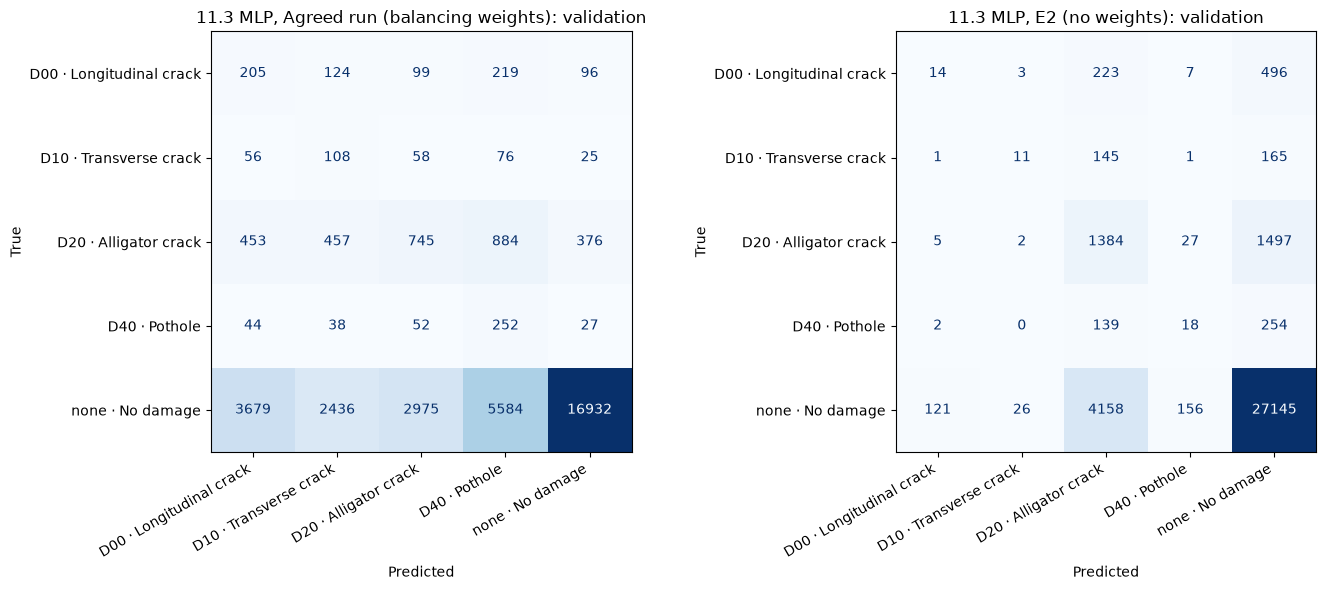

saved e2_no_sample_weights.joblib (1.07 MB), e2_results.json, e2_vs_agreed_confusion.png


In [8]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, precision_recall_fscore_support
from ml.training import LABELS, NAMES

pred_a, pred_e2 = final.predict(X_va), e2.predict(X_va)

def per_class(pred):
    p, r, f, _ = precision_recall_fscore_support(y_va, pred, labels=LABELS, zero_division=0)
    return pd.DataFrame({"precision": p, "recall": r, "F1": f,
                         "times predicted": np.bincount(pred, minlength=len(LABELS))}, index=config.CLASSES)

pa, pe = per_class(pred_a), per_class(pred_e2)
side = pd.concat({"agreed (weights)": pa, "E2 (no weights)": pe}, axis=1)
side[("change", "F1")] = pe["F1"] - pa["F1"]
side[("change", "recall")] = pe["recall"] - pa["recall"]
side[("", "true count")] = np.bincount(y_va, minlength=len(LABELS))
print(side.round(3).to_string())

# Where does E2's macro F1 gain come from? (macro F1 = mean of the 5 class F1s, so each class adds change / 5)
gain = (side[("change", "F1")] / len(LABELS)).round(4)
print("\nshare of the macro F1 change per class:", gain.to_dict(),
      f"| total {gain.sum():+.4f}")
damage = [c for c in config.CLASSES if c != "none"]
print(f"damage classes only: mean F1 {pa.loc[damage, 'F1'].mean():.3f} (agreed) -> "
      f"{pe.loc[damage, 'F1'].mean():.3f} (E2) | mean recall {pa.loc[damage, 'recall'].mean():.3f} -> "
      f"{pe.loc[damage, 'recall'].mean():.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, pred, title in [(axes[0], pred_a, "Agreed run (balancing weights)"), (axes[1], pred_e2, "E2 (no weights)")]:
    ConfusionMatrixDisplay(confusion_matrix(y_va, pred, labels=LABELS), display_labels=NAMES).plot(
        ax=ax, cmap="Blues", values_format="d", colorbar=False)
    ax.set(title=f"11.3 MLP, {title}: validation", xlabel="Predicted", ylabel="True")
    plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
fig.tight_layout()
fig.savefig(OUT / "e2_vs_agreed_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

# Keep E2 as an alternative, under its own name (best_pipeline.joblib stays the agreed run)
joblib_path = OUT / "e2_no_sample_weights.joblib"
import joblib
joblib.dump(e2, joblib_path)
cm_e2 = confusion_matrix(y_va, pred_e2, labels=LABELS)
(OUT / "e2_results.json").write_text(json.dumps({
    "model": "11.3 MLP, E2 no sample weights (alternative, not the Phase 11 result)",
    "best_params": {k.replace("clf__", ""): str(v) for k, v in params.items()},
    "val_macro_f1": round(float(f1_score(y_va, pred_e2, average="macro")), 4),
    "per_class": {c: {"precision": round(float(pe.loc[c, "precision"]), 4), "recall": round(float(pe.loc[c, "recall"]), 4),
                      "f1": round(float(pe.loc[c, "F1"]), 4)} for c in config.CLASSES},
    "confusion_matrix": cm_e2.tolist(),
}, indent=2))
print(f"saved {joblib_path.name} ({joblib_path.stat().st_size / 1e6:.2f} MB), e2_results.json, e2_vs_agreed_confusion.png")

### 7c. The rest of the Phase 12 checklist (the cheap rows)

The agreed run has two problems: some memorising (0.09) and many false alarms on clean road (0.09). Each try below changes **one** thing against the agreed run; everything else stays as in step 5.

| Phase 12 row / experiment | Try here |
|---|---|
| Scores jump between seeds | Refit with 3 seeds: this is the **noise level**; a "better" try must beat it |
| One country is much worse | Macro F1 per country (Czech, India, Japan) |
| Overfitting: larger α | α = 0.1 |
| Overfitting: fewer PCA components | PCA 30 |
| H2: HOG vs 5 measures vs both | HOG only (PCA 60), 5 measures only (no PCA) |
| H2: PCA 20 / 60 / 120 | PCA 20 (60 is the agreed run, 120 was E3) |
| H3: balanced vs unbalanced training data | All training squares before Phase 8, with and without weights |

Not run here: "almost always predicts none" and "pothole recall is low" do not apply (pothole recall is 0.61); "training takes forever" does not apply (5 s). A texture measure, HOG with 16 × 16 cells and a higher label threshold need Phases 6–9 rebuilt for everyone, so they are a team decision.

**Keep rule:** better than the agreed run by more than the seed spread. A try that changes the shared data, features or PCA is marked "ask team" even when it wins.

seed 42                            val macro F1 0.2234 | D40 recall 0.610 | none flagged 46.4% | 3 s


seed 1                             val macro F1 0.2186 | D40 recall 0.446 | none flagged 47.9% | 4 s


seed 2                             val macro F1 0.2332 | D40 recall 0.467 | none flagged 46.9% | 3 s
-> agreed run over 3 seeds: 0.2251 ± 0.0061 (spread 0.0146)

       squares  val macro F1  D40 recall  none flagged
Czech  11840.0        0.2002       0.467         0.354
India  12880.0        0.1815       0.663         0.504
Japan  11280.0        0.2191       0.311         0.556 



alpha 0.1                          val macro F1 0.2216 | D40 recall 0.557 | none flagged 49.0% | 3 s


PCA 30                             val macro F1 0.2271 | D40 recall 0.491 | none flagged 48.8% | 4 s


PCA 20                             val macro F1 0.2333 | D40 recall 0.506 | none flagged 46.0% | 3 s


H2 HOG only                        val macro F1 0.2247 | D40 recall 0.605 | none flagged 46.4% | 3 s


H2 5 measures only                 val macro F1 0.2304 | D40 recall 0.482 | none flagged 44.9% | 5 s


unbalanced train: 168,000 squares | per class {'D00': np.int64(3231), 'D10': np.int64(1819), 'D20': np.int64(13076), 'D40': np.int64(2130), 'none': np.int64(147744)}


H3 unbalanced, no weights          val macro F1 0.1870 | D40 recall 0.000 | none flagged 0.0% | 14 s


H3 unbalanced + weights            val macro F1 0.2259 | D40 recall 0.550 | none flagged 47.8% | 14 s


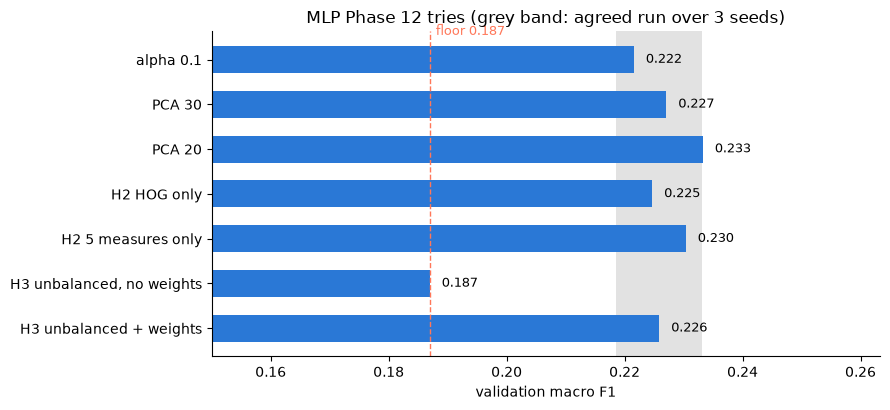

,try,change,val_macro_f1,d40_recall,d40_precision,none_flagged,fit_s,vs agreed,keep?
0,seed 42,random_state=42,0.2234,0.6102,0.0359,0.4643,3.1,0.0000,noise check
1,seed 1,random_state=1,0.2186,0.4455,0.0358,0.4794,3.6,-0.0048,noise check
2,seed 2,random_state=2,0.2332,0.4673,0.0405,0.4689,3.3,0.0098,noise check
3,alpha 0.1,alpha=0.1,0.2216,0.5569,0.0358,0.4902,3.3,-0.0018,no
4,PCA 30,n_components=30,0.2271,0.4915,0.0400,0.4883,4.1,0.0037,within noise
5,PCA 20,n_components=20,0.2333,0.5061,0.0424,0.4600,3.4,0.0099,within noise
6,H2 HOG only,"columns 0-1763, PCA 60",0.2247,0.6053,0.0380,0.4641,3.2,0.0013,within noise
7,H2 5 measures only,"columns 1764-1768, no PCA",0.2304,0.4818,0.0324,0.4486,4.7,0.0070,within noise
8,"H3 unbalanced, no weights","all train squares, no weights",0.1870,0.0000,0.0000,0.0000,14.3,-0.0364,no
9,H3 unbalanced + weights,"all train squares, balanced weights",0.2259,0.5496,0.0372,0.4777,14.1,0.0025,within noise


In [9]:
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from ml.training import load_unbalanced_train

def mlp(seed=SEED, **change):
    kw = {k.replace("clf__", ""): v for k, v in params.items()} | change   # the step-5 settings, plus one change
    return MLPClassifier(early_stopping=True, random_state=seed, **kw)

tries = []
def run(name, change, model, X_fit, y_fit, w=None, cols=slice(None), shared=False):
    t = time.perf_counter()
    model.fit(X_fit[:, cols], y_fit, **({"clf__sample_weight": w} if w is not None else {}))
    row = score(name, model.predict(X_va[:, cols]), change)
    row |= {"fit_s": round(time.perf_counter() - t, 1), "shared": shared}
    tries.append(row)
    print(f"{name:34s} val macro F1 {row['val_macro_f1']:.4f} | D40 recall {row['d40_recall']:.3f} "
          f"| none flagged {row['none_flagged']:.1%} | {row['fit_s']:.0f} s")

# 1) noise level: the agreed run with 3 seeds (42 is step 5 itself)
for s in (42, 1, 2):
    run(f"seed {s}", f"random_state={s}", make_pipeline(mlp(seed=s)), X_tr, y_tr, w_tr)
seed_f1 = np.array([r["val_macro_f1"] for r in tries])
noise = seed_f1.max() - seed_f1.min()
print(f"-> agreed run over 3 seeds: {seed_f1.mean():.4f} ± {seed_f1.std():.4f} (spread {noise:.4f})\n")

# 2) one country much worse?
country = np.array([s.split("_")[0] for s in meta["image_id"][meta["split"] == "val"]])
assert len(country) == len(y_va)
pred_a = final.predict(X_va)
by_country = pd.DataFrame({c: {"squares": int((country == c).sum()),
                               "val macro F1": round(f1_score(y_va[country == c], pred_a[country == c], average="macro"), 4),
                               "D40 recall": round(recall_score(y_va[country == c], pred_a[country == c], labels=[D40], average="macro", zero_division=0), 3),
                               "none flagged": round(float(np.mean(pred_a[(country == c) & (y_va == NONE)] != NONE)), 3)}
                           for c in sorted(set(country))}).T
print(by_country.to_string(), "\n")

# 3) overfitting row: more regularisation, fewer components
run("alpha 0.1", "alpha=0.1", make_pipeline(mlp(alpha=0.1)), X_tr, y_tr, w_tr)
run("PCA 30", "n_components=30", make_pipeline(mlp(), n_components=30), X_tr, y_tr, w_tr, shared=True)

# 4) H2: which features carry the signal? (PCA 120 was E3)
run("PCA 20", "n_components=20", make_pipeline(mlp(), n_components=20), X_tr, y_tr, w_tr, shared=True)
run("H2 HOG only", "columns 0-1763, PCA 60", make_pipeline(mlp()), X_tr, y_tr, w_tr, cols=slice(0, 1764), shared=True)
run("H2 5 measures only", "columns 1764-1768, no PCA",
    Pipeline([("scale", StandardScaler()), ("clf", mlp())]), X_tr, y_tr, w_tr, cols=slice(1764, 1769), shared=True)

# 5) H3: all training squares before Phase 8's balancing (about 88% none)
X_un, y_un = load_unbalanced_train()
print(f"unbalanced train: {len(y_un):,} squares | per class", dict(zip(config.CLASSES, np.bincount(y_un))))
run("H3 unbalanced, no weights", "all train squares, no weights", make_pipeline(mlp()), X_un, y_un, shared=True)
run("H3 unbalanced + weights", "all train squares, balanced weights", make_pipeline(mlp()), X_un, y_un,
    compute_sample_weight("balanced", y_un), shared=True)
del X_un

# Log and verdict against the agreed run
t7c = pd.DataFrame(tries)
agreed = t7c.loc[0, "val_macro_f1"]
t7c["vs agreed"] = (t7c["val_macro_f1"] - agreed).round(4)
t7c["keep?"] = np.select(
    [t7c["try"].str.startswith("seed"), t7c["vs agreed"] <= 0, t7c["vs agreed"] <= noise, t7c["shared"]],
    ["noise check", "no", "within noise", "ask team"], "yes")
pd.concat([exp, t7c], ignore_index=True).to_csv(OUT / "experiments_log.csv", index=False)

fig, ax = plt.subplots(figsize=(9, 4.2))
plot = t7c[~t7c["try"].str.startswith("seed")].iloc[::-1]
ax.axvspan(seed_f1.min(), seed_f1.max(), color="#8c8c8c", alpha=.25, lw=0)
ax.barh(plot["try"], plot["val_macro_f1"], color="#2a78d6", height=.6)
for y_pos, v in enumerate(plot["val_macro_f1"]):
    ax.text(v + .002, y_pos, f"{v:.3f}", va="center", fontsize=9)
ax.axvline(0.187, ls="--", lw=1, color="#ff7759")
ax.text(0.188, len(plot) - .45, "floor 0.187", color="#ff7759", fontsize=9)
ax.set(xlim=(0.15, max(plot["val_macro_f1"].max(), seed_f1.max()) + .03), xlabel="validation macro F1",
       title="MLP Phase 12 tries (grey band: agreed run over 3 seeds)")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(OUT / "phase12_tries.png", dpi=150, bbox_inches="tight")
plt.show()

t7c.drop(columns=["shared"])


## 8. Save and hand in

`joblib.dump(...)` the final pipeline to `OUT / "best_pipeline.joblib"`. Then import `results.json` in the Results sheet tab of the team plan, add your observations and download the PDF.

In [10]:
import joblib

# the Phase 11 model (step 5): the one in results.json and in the team comparison
joblib.dump(final, OUT / "best_pipeline.joblib")
for f in sorted(OUT.iterdir()):
    if f.is_file():
        print(f"{f.name:24s} {f.stat().st_size / 1e6:8.2f} MB")


best_pipeline.joblib         1.08 MB
confusion_matrix.png         0.07 MB
cv_results.csv               0.00 MB
e2_no_sample_weights.joblib     1.07 MB
e2_results.json              0.00 MB
e2_vs_agreed_confusion.png     0.14 MB
experiments_log.csv          0.00 MB
grid_heatmap.png             0.06 MB
loss_curve.png               0.08 MB
phase12_tries.png            0.05 MB
results.json                 0.00 MB
run_log.json                 0.00 MB
